# Loading the Libraries

In [32]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, FunctionTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy.sparse import hstack
from scipy.sparse import csr_matrix
from matplotlib.colors import ListedColormap
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    ConfusionMatrixDisplay, confusion_matrix,
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report
)

# Use a consistent style for all charts in this notebook.
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

print(f"Python: {sys.version.split()[0]}")
print(f"NumPy: {np.__version__}")
print(f"pandas: {pd.__version__}")

print("\n✓ Environment check passed")

RANDOM_STATE = 42

Python: 3.14.2
NumPy: 2.5.3
pandas: 3.0.5

✓ Environment check passed


# Loading the data

In [33]:
# Load the dataset
df = pd.read_csv('../original_data/DataSet_AIvsHuman.csv')
df.head()


,id,prompt,content,type,source,label,topic,word_count,char_count,ai_model,language,complexity_score,is_multiline_code
0,1,Write a string manipulation solution in python,def string_manipulation():\n # TODO: implem...,code,blog,human,string manipulation,9,84,NaN,python,3,True
1,2,Explain health in simple terms,Experts recommend focusing on health to improv...,text,generated,ai,health,29,211,Claude,en,3,False
2,3,Summarize recent developments in finance,The development of finance technologies has ac...,text,generated,ai,finance,56,419,GPT-4,en,5,False
3,4,Summarize recent developments in finance,Recent studies show that finance can have sign...,text,generated,ai,finance,42,298,Claude,en,10,False
4,5,Provide a graph traversal algorithm in cpp,vector<int> arr; // graph traversal example\nf...,code,generated,ai,graph traversal,11,98,Gemini,cpp,10,True


# Splitting the data into text only

In [34]:

df_text = df[df["type"].str.lower() == "text"]
df_text.head()
print("rows, columns:", df_text.shape)

#df_text.select_dtypes("number").hist(figsize=(10, 6), bins=30, edgecolor="white")
#plt.tight_layout()
#plt.show()
df_text.info()

rows, columns: (10004, 13)
<class 'pandas.DataFrame'>
Index: 10004 entries, 1 to 19992
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   id                 10004 non-null  int64
 1   prompt             10004 non-null  str  
 2   content            10004 non-null  str  
 3   type               10004 non-null  str  
 4   source             10004 non-null  str  
 5   label              10004 non-null  str  
 6   topic              10004 non-null  str  
 7   word_count         10004 non-null  int64
 8   char_count         10004 non-null  int64
 9   ai_model           5067 non-null   str  
 10  language           10004 non-null  str  
 11  complexity_score   10004 non-null  int64
 12  is_multiline_code  10004 non-null  bool 
dtypes: bool(1), int64(4), str(8)
memory usage: 4.6 MB


In [35]:
# Check duplicates
print(df_text.duplicated(subset=["content"]).sum())

# Remove duplicates
df_text = df_text.drop_duplicates(subset=["content"])

# Verify
print(df_text.duplicated(subset=["content"]).sum())
print(df_text.shape)


1812
0
(8192, 13)


# Preprocessing and Feature Engineering
## Adding Feautures

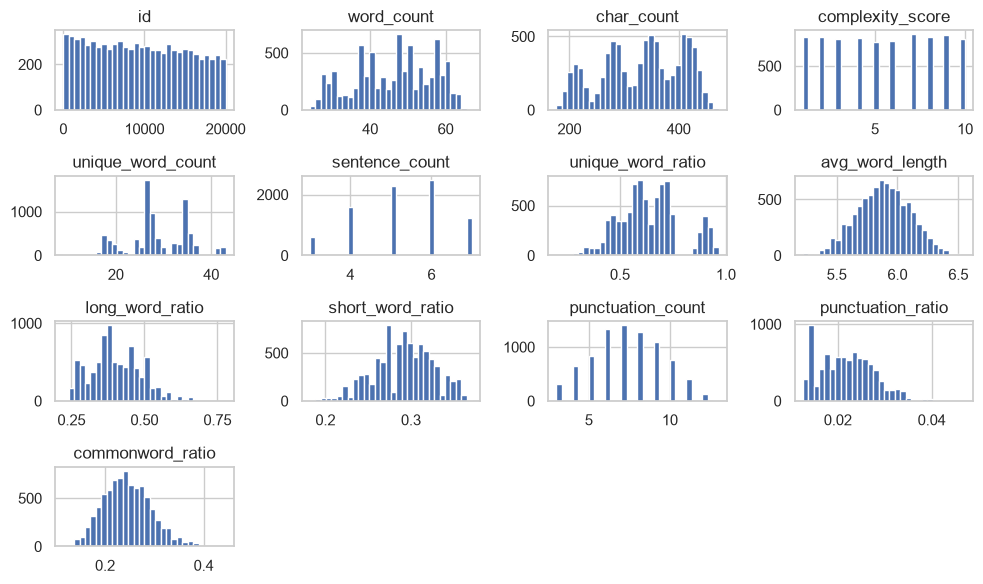

rows, columns: (8192, 22)


In [36]:
# Human vs AI Text Only Data

# Count unique words in each content entry
df_text["unique_word_count"] = df_text["content"].fillna("").apply(
    lambda text: len(
        set(
            re.findall(r"\b\w+\b", text.lower())
        )
    )
)

# Sentence count
df_text["sentence_count"] = df_text["content"].fillna("").apply(
    lambda x: len([s for s in re.split(r"[.!?]+", str(x)) if s.strip()])
)

# Unique word ratio
# A low value (e.g. 0.3-0.5) indicates lots of repeated words.
# A high value (e.g. 0.8-1.0) indicates a more varied vocabulary.
df_text["unique_word_ratio"] = df_text["unique_word_count"] / df_text["word_count"].replace(0, 1)

# Average word length
df_text["avg_word_length"] = df_text["content"].fillna("").apply(
    lambda x: (
        sum(len(word) for word in re.findall(r"\b\w+\b", str(x)))
        / max(len(re.findall(r"\b\w+\b", str(x))), 1)
    )
)

# long word ratio
df_text["long_word_ratio"] = df_text["content"].fillna("").apply(
    lambda x: (
        sum(1 for word in re.findall(r"\b\w+\b", str(x)) if len(word) > 6)
        / max(len(re.findall(r"\b\w+\b", str(x))), 1)
    )
)

# short word ratio
df_text["short_word_ratio"] = df_text["content"].fillna("").apply(
    lambda x: (
        sum(1 for word in re.findall(r"\b\w+\b", str(x)) if len(word) <= 3)
        / max(len(re.findall(r"\b\w+\b", str(x))), 1)
    )
)

# punctuation count
df_text["punctuation_count"] = df_text["content"].fillna("").apply(
    lambda x: len(re.findall(r"[^\w\s]", str(x)))
)

# punctuation ratio
df_text["punctuation_ratio"] = df_text["content"].fillna("").apply(
    lambda x: len(re.findall(r"[^\w\s]", str(x)))
) / df_text["char_count"].replace(0, 1)

# common word ratio
common_words = {
    "a", "an", "the", "and", "or", "but", "if", "is", "are", "was",
    "were", "be", "been", "being", "to", "of", "in", "on", "for",
    "with", "as", "at", "by", "from", "that", "this", "it"
}

df_text["commonword_ratio"] = df_text["content"].fillna("").apply(
    lambda text: (
        lambda words: (
            sum(word in common_words for word in words) / len(words)
            if words else 0
        )
    )(re.findall(r"\b[A-Za-z']+\b", str(text).lower()))
)

# semi-colon ratio (looked at adding it as a feature but both files had zero semicolons)

# results visualised
df_text.select_dtypes("number").hist(figsize=(10, 6), bins=30, edgecolor="white")
plt.tight_layout()
plt.show()

print("rows, columns:", df_text.shape)
#df_text.to_csv("../created_data/df_text.csv", index=False)

In [37]:
df_text.info()

<class 'pandas.DataFrame'>
Index: 8192 entries, 1 to 19992
Data columns (total 22 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 8192 non-null   int64  
 1   prompt             8192 non-null   str    
 2   content            8192 non-null   str    
 3   type               8192 non-null   str    
 4   source             8192 non-null   str    
 5   label              8192 non-null   str    
 6   topic              8192 non-null   str    
 7   word_count         8192 non-null   int64  
 8   char_count         8192 non-null   int64  
 9   ai_model           4142 non-null   str    
 10  language           8192 non-null   str    
 11  complexity_score   8192 non-null   int64  
 12  is_multiline_code  8192 non-null   bool   
 13  unique_word_count  8192 non-null   int64  
 14  sentence_count     8192 non-null   int64  
 15  unique_word_ratio  8192 non-null   float64
 16  avg_word_length    8192 non-null   floa

## Target Leakage
> removing all non-numeric columns

In [38]:
target = "label"

leaky_cols = ["source", "ai_model", "language", "type", "is_multiline_code", "prompt", "content", "topic"]
id_cols = ["id"]

X = df_text.drop(columns=[target] + leaky_cols + id_cols)
y = df_text[target]
print("Features used:", X.columns.tolist())

X.head()
print("rows, columns:", X.shape)

Features used: ['word_count', 'char_count', 'complexity_score', 'unique_word_count', 'sentence_count', 'unique_word_ratio', 'avg_word_length', 'long_word_ratio', 'short_word_ratio', 'punctuation_count', 'punctuation_ratio', 'commonword_ratio']
rows, columns: (8192, 12)


# Train/Test Split

In [39]:
# Keep 20% of the rows aside. random_state makes this split reproducible.
# Created from 'leakagefree_data.csv'
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("train:", X_train.shape, " test:", X_test.shape)

train: (6553, 12)  test: (1639, 12)


In [40]:
X.info()

<class 'pandas.DataFrame'>
Index: 8192 entries, 1 to 19992
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   word_count         8192 non-null   int64  
 1   char_count         8192 non-null   int64  
 2   complexity_score   8192 non-null   int64  
 3   unique_word_count  8192 non-null   int64  
 4   sentence_count     8192 non-null   int64  
 5   unique_word_ratio  8192 non-null   float64
 6   avg_word_length    8192 non-null   float64
 7   long_word_ratio    8192 non-null   float64
 8   short_word_ratio   8192 non-null   float64
 9   punctuation_count  8192 non-null   int64  
 10  punctuation_ratio  8192 non-null   float64
 11  commonword_ratio   8192 non-null   float64
dtypes: float64(6), int64(6)
memory usage: 832.0 KB


# Scaling numeric Values

In [41]:

numeric_cols = ["word_count",
    "char_count",
    "complexity_score",
    "unique_word_count",
    "sentence_count",
    "unique_word_ratio",
    "avg_word_length",
    "long_word_ratio",
    "short_word_ratio",
    "punctuation_count",
    "punctuation_ratio",
    "commonword_ratio",
]
print("Ranges before scaling:")
print(X_train[numeric_cols].agg(["min", "max"]))

# The scaler learns the mean and standard deviation from training data only.
scaler = StandardScaler()
X_train[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])

# The test set uses those same training values; it must not calculate new ones.
X_test[numeric_cols] = scaler.transform(X_test[numeric_cols])

print("\nTraining means after scaling:")
print(X_train[numeric_cols].mean().round(2))

Ranges before scaling:
     word_count  char_count  complexity_score  unique_word_count  \
min          24         176                 1                  9   
max          67         473                10                 43   

     sentence_count  unique_word_ratio  avg_word_length  long_word_ratio  \
min               3           0.200000         5.222222         0.222222   
max               7           0.965517         6.555556         0.777778   

     short_word_ratio  punctuation_count  punctuation_ratio  commonword_ratio  
min          0.181818                  3           0.012552          0.115385  
max          0.371429                 13           0.047120          0.444444  

Training means after scaling:
word_count           0.0
char_count          -0.0
complexity_score     0.0
unique_word_count    0.0
sentence_count       0.0
unique_word_ratio    0.0
avg_word_length      0.0
long_word_ratio      0.0
short_word_ratio    -0.0
punctuation_count    0.0
punctuation_ratio    0

# Train a Logistic Regression classifier

In [42]:
log_reg = make_pipeline(
    StandardScaler(),
    LogisticRegression(random_state=RANDOM_STATE)
)

log_reg.fit(X_train, y_train)

log_predictions = log_reg.predict(X_test)
log_probabilities = log_reg.predict_proba(X_test)[:, 1]


print("First 20 predicted classes:", log_predictions[:20])
print("First 20 probabilities of Pass:", np.round(log_probabilities[:20], 2))
print("Test accuracy:", round(accuracy_score(y_test, log_predictions), 3))

First 20 predicted classes: ['human' 'human' 'ai' 'ai' 'ai' 'ai' 'human' 'human' 'human' 'human'
 'human' 'human' 'ai' 'ai' 'ai' 'human' 'human' 'ai' 'human' 'human']
First 20 probabilities of Pass: [0.97 1.   0.   0.   0.   0.16 0.99 1.   1.   1.   0.99 0.99 0.04 0.01
 0.27 0.99 1.   0.01 0.93 0.85]
Test accuracy: 0.984


# Train a K-Nearest Neighbours classifier

### The idea

KNN is based on a simple principle: **similar students tend to have similar outcomes**. To predict for a new student:

1. Measure how far the new student is from every student in the training set (using their hours studied and attendance).
2. Pick the `k` closest students, their "nearest neighbours". Here `k = 5`.
3. Look at the neighbours' outcomes and take a **majority vote**. If 4 of the 5 neighbours passed, predict Pass.

KNN does not learn weights or draw a line. It simply stores the training data and looks things up when asked. The choice of `k` is up to us; we explore it in section 9.

### Why scaling matters here

"Distance" depends on the units of the features. Attendance ranges roughly from 35 to 100 (a spread of about 65), while study hours range from 0 to 12 (a spread of about 12). Without scaling, a difference of 10 percentage points in attendance would count the same as a difference of 10 hours of study, even though 10 hours is a huge difference and 10 percentage points is not. Attendance would dominate the distance, and study hours would be nearly ignored.

Scaling puts both features on a comparable footing, so each contributes fairly. As before, the pipeline fits the scaler on training data only.

In [44]:
knn = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)

knn.fit(X_train, y_train)
knn_predictions = knn.predict(X_test)

print("First 10 predicted classes:", knn_predictions[:10])
print("Test accuracy:", round(accuracy_score(y_test, knn_predictions), 3))

First 10 predicted classes: ['human' 'human' 'ai' 'ai' 'ai' 'ai' 'human' 'human' 'human' 'human']
Test accuracy: 0.983


# Compare the two models

We evaluate both models on exactly the same test observations, so the comparison is fair. **Accuracy** is the proportion of test observations classified correctly. It is useful for this introduction, although it is not sufficient for every real classification problem (for example, when one class is very rare).

In [45]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "KNN (k=5)"],
    "Test accuracy": [
        accuracy_score(y_test, log_predictions),
        accuracy_score(y_test, knn_predictions)
    ]
}).sort_values("Test accuracy", ascending=False)

results

,Model,Test accuracy
0,Logistic Regression,0.983527
1,KNN (k=5),0.982916


# What changes when we change `k`?

In KNN, `k` is the number of neighbours that vote. It is a setting we choose ourselves, not something the model learns.

- **Small `k` (e.g. 1)**: the prediction depends on just one neighbour, so the model reacts to every individual student, including unusual ones and random noise. The boundary becomes very irregular. The model can fit the training data almost perfectly but may not work well on new students. This is called **overfitting**.
- **Large `k` (e.g. 20)**: many neighbours vote, so individual unusual students have little influence. The boundary becomes smooth, but if `k` is too large the model may ignore genuine local patterns (**underfitting**).

Train KNN with different values of `k` and compare the test accuracy and decision boundaries.

**Before running the cell, predict:** Which value of `k` will produce the most irregular boundary? Which will produce the smoothest?

In [46]:
k_values = [1, 5, 20, 300, 500, 1000, 2000, 3000, 4000, 5000]
knn_models = {}
k_results = []

for k in k_values:
    model = make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=k)
    )
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    knn_models[k] = model
    k_results.append({
        "k": k,
        "Test accuracy": accuracy_score(y_test, predictions)
    })

pd.DataFrame(k_results)

,k,Test accuracy
0,1,0.991458
1,5,0.982916
2,20,0.970104
3,300,0.928615
4,500,0.924344
5,1000,0.916412
6,2000,0.893228
7,3000,0.865162
8,4000,0.810860
9,5000,0.757169


# Key takeaways

### Logistic Regression vs KNN

| | **Logistic Regression** | **K-Nearest Neighbours (KNN)** |
|---|---|---|
| **Main idea** | Learns a weight for each feature and combines them into a score | Finds the `k` most similar training observations and takes a majority vote |
| **What is learned** | Weights (one per feature), learned during training | Nothing: it stores the training data and looks things up at prediction time |
| **Output** | A probability of the positive class, then a class using a threshold (0.5 by convention) | A class from a vote among the neighbours |
| **Decision boundary** | A straight line (in 2 features) | Can be curvy and irregular, following local neighbourhoods |
| **Setting we choose** | The threshold (and other settings we did not use here) | `k`, the number of neighbours |
| **Effect of that setting** | Moving the threshold changes how cautious the model is about predicting Pass | Small `k`: irregular boundary, risk of overfitting. Large `k`: smooth boundary, risk of underfitting |
| **Scaling the features** | Helpful, but not essential | Important: distances depend on units, so unscaled features can dominate |
| **Interpretability** | The weights show how each feature pushes the prediction up or down | Easy to explain ("students like this one passed"), but there are no weights to inspect |
| **Prediction speed** | Fast | Slower on large datasets, since it compares against the stored training data |



# Train a Decision Tree classifier

## Fit a small decision tree

A tree asks questions about one feature at a time. Each split divides the data into groups; each leaf gives a prediction.

Trees compare thresholds rather than distances, so **no feature scaling is needed**.

In [47]:
# max_depth limits how many questions the tree may ask in a row
tree = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE)
tree.fit(X_train, y_train)

print("Training accuracy:", round(tree.score(X_train, y_train), 2))
print("Test accuracy:", round(tree.score(X_test, y_test), 2))

Training accuracy: 0.92
Test accuracy: 0.91


### Read the tree

Each box shows:
- the **question** (e.g. `study_hours <= 4.6`): go left if true, right if false
- **gini**: how mixed the group is (0 = all one class, 0.5 = a 50/50 mix)
- **samples**: how many training students reach this box
- **value**: how many of them are [Fail, Pass]
- **class**: the majority class, which is the prediction at a leaf

The tree picks each question to make the groups below it as pure as possible (lowest size-weighted gini).

> **Which measure is used?** scikit-learn's default is `criterion="gini"` (Gini impurity). The alternative is `criterion="entropy"`.
> - **Gini** = the chance that a randomly chosen student in the box would be mislabelled if we guessed a label at random according to the box's Pass/Fail proportions.
> - **Entropy** measures "surprise" or disorder: how many yes/no questions you would need, on average, to work out a student's label.
>
> Both are 0 for a pure group and largest for a 50/50 mix, so in practice they usually choose very similar splits. Gini is the default because it is slightly cheaper to compute. You can try `DecisionTreeClassifier(criterion="entropy")` to compare.


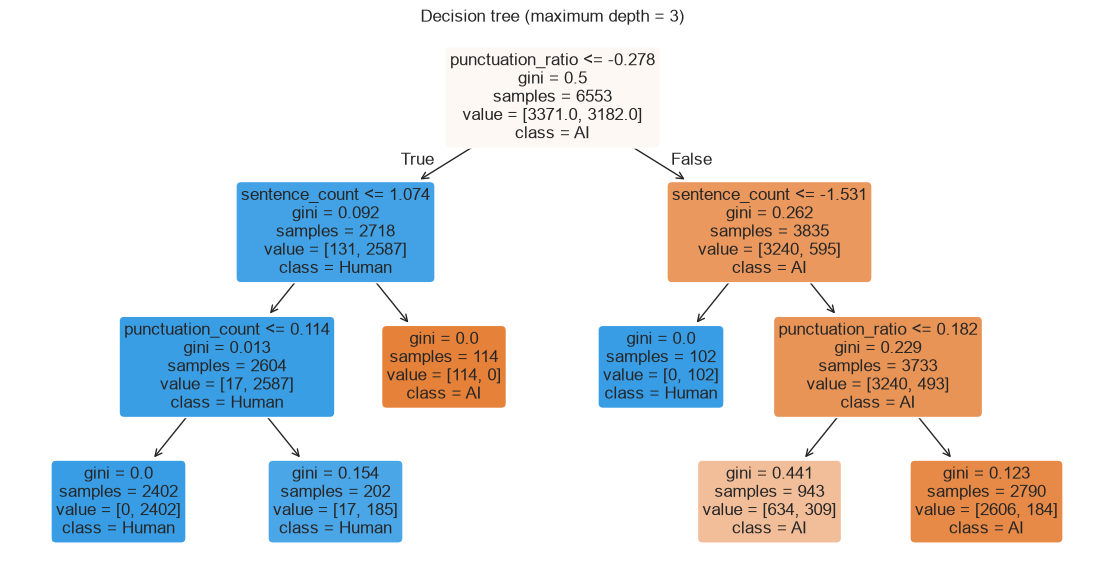

In [48]:
plt.figure(figsize=(14, 7))
plot_tree(
    tree,
    feature_names=X.columns,
    class_names=["AI", "Human"],
    filled=True,       # colour boxes by majority class
    rounded=True,
    proportion=False   # show counts, not fractions
)
plt.title("Decision tree (maximum depth = 3)")
plt.show()

The decision tree revealed that punctuation-related features were the strongest predictors of class membership. The root node split on punctuation ratio, indicating that differences in punctuation usage constituted the primary distinction between AI-generated and human-authored texts in the dataset. Subsequent splits used punctuation count and sentence count. The resulting shallow tree (maximum depth = 3) achieved near-perfect separation, suggesting that the dataset contains highly discriminative stylistic features and may be easier to classify than real-world AI detection tasks.

## Visualise the decision boundary

We predict the class for every point on a fine grid and colour the background by the prediction. Because each split asks about one feature, the regions are rectangles.

In [49]:
from sklearn.tree import DecisionTreeClassifier

X_train_2d = X_train[[
    "punctuation_ratio",
    "sentence_count"
]]

X_test_2d = X_test[[

    "punctuation_ratio",
    "sentence_count"
]]

tree_2d = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

tree_2d.fit(X_train_2d, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in

c:\Users\eabha\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


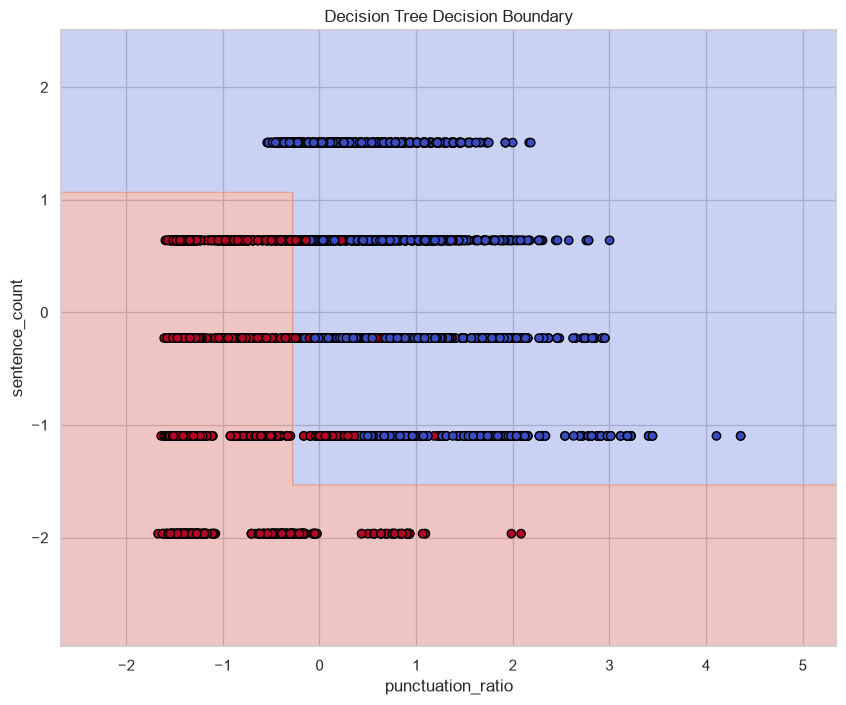

In [50]:
import numpy as np
import matplotlib.pyplot as plt

x_min, x_max = X_train_2d.iloc[:, 0].min() - 1, X_train_2d.iloc[:, 0].max() + 1
y_min, y_max = X_train_2d.iloc[:, 1].min() - 1, X_train_2d.iloc[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.arange(x_min, x_max, 0.01),
    np.arange(y_min, y_max, 0.01)
)

Z = tree_2d.predict(
    np.c_[xx.ravel(), yy.ravel()]
)

# Convert labels if needed
Z = np.where(Z == "human", 1, 0)

Z = Z.reshape(xx.shape)

plt.figure(figsize=(10,8))

plt.contourf(
    xx,
    yy,
    Z,
    alpha=0.3,
    cmap="coolwarm"
)

scatter = plt.scatter(
    X_train_2d["punctuation_ratio"],
    X_train_2d["sentence_count"],
    c=(y_train == "human"),
    cmap="coolwarm",
    edgecolor="black"
)

plt.xlabel("punctuation_ratio")
plt.ylabel("sentence_count")
plt.title("Decision Tree Decision Boundary")
plt.show()

## Core investigation: tree depth

**Before running the code:** predict what will happen to training and test accuracy as depth increases.

In [ ]:
# Fit one tree per depth and record both scores
results = []
for depth in range(1, 21):
    model = DecisionTreeClassifier(max_depth=depth, random_state=RANDOM_STATE)
    model.fit(X_train, y_train)
    results.append({
        "max_depth": depth,
        "Training accuracy": model.score(X_train, y_train),
        "Test accuracy": model.score(X_test, y_test),
        "Leaves": model.get_n_leaves()   # number of final groups = how complex the tree is
    })

tree_results = pd.DataFrame(results)
tree_results

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(tree_results["max_depth"], tree_results["Training accuracy"], marker="o", label="Training")
ax.plot(tree_results["max_depth"], tree_results["Test accuracy"], marker="o", label="Test")
ax.set_xlabel("Maximum tree depth")
ax.set_ylabel("Accuracy")
ax.set_title("Model complexity and generalisation")
ax.set_xticks(range(1, 21, 2))
ax.grid(alpha=0.25)
ax.legend()
plt.show()

In [ ]:
best = tree_results.loc[tree_results["Test accuracy"].idxmax()]
print("Best depth on this test set:", int(best["max_depth"]))
print("Test accuracy:", round(best["Test accuracy"], 3))

### Interpret the results

- Training accuracy rises with depth because the tree can make ever more specific rules, until it memorises the training set (100%).
- Test accuracy peaks and then falls once the tree starts fitting noise: that is **overfitting**.
- Once the tree stops growing (the number of leaves stops changing), extra depth changes nothing.
- With only ~60 test students, the test curve is bumpy: one student is worth almost 2 percentage points.

> **Caveat:** choosing the depth by looking at the test set makes the test set less "unseen". Week 10 introduces cross-validation, the proper way to choose settings like this.

## Key takeaways

- Decision trees classify using a sequence of yes/no questions, one feature at a time.
- Tree boundaries are made from axis-aligned rectangles.
- Greater depth increases flexibility but can lead to overfitting.
- Compare training and test accuracy: a large gap signals overfitting.

# Model Evaluation
## Comparing classification models fairly

In this notebook, we will practise the evaluation ideas from Lecture 8:

- Why performance on training data is not enough
- The roles of training, validation and test sets
- Confusion matrices, accuracy, precision, recall and F1
- Cross-validation for fair model comparison
- Avoiding data leakage with a `Pipeline`

We use a **simulated student-support dataset**. It is artificial and is only for practising machine-learning methods; it does not describe real students and should not be used to make decisions about people.

In [ ]:
# Inspect the class balance as proportions.
y.value_counts(normalize=True).sort_index()

## Split the data before fitting a model

The **training set** is used to fit model parameters. The **validation set** (or cross-validation) helps compare models and tune settings. The **test set** is held back for a final, independent estimate.

Here we make a 60% training, 20% validation and 20% test split. `stratify=y` helps preserve the class proportions in each split.

In [ ]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.40, random_state=RANDOM_STATE, stratify=y
)
X_valid, X_test, y_valid, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=RANDOM_STATE, stratify=y_temp
)

print(f"Train:      {len(X_train):4d} rows ({len(X_train)/len(X):.0%})")
print(f"Validation: {len(X_valid):4d} rows ({len(X_valid)/len(X):.0%})")
print(f"Test:       {len(X_test):4d} rows ({len(X_test)/len(X):.0%})")

## Compare a few classifiers on validation data

We will compare Logistic Regression, K-Nearest Neighbours (KNN), and a Decision Tree. Scaling matters for Logistic Regression and KNN, so those models use a pipeline. The scaler is fitted only on the training data.

We use the validation set for model comparison here. We will not use the test set to choose the winner.

In [ ]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

y_train_encoded = le.fit_transform(y_train)
y_valid_encoded = le.transform(y_valid)

models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
    ]),
    "KNN (k=15)": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=15))
    ]),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=5, random_state=RANDOM_STATE
    )
}

validation_rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_valid)
    validation_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_valid, pred),
        "Precision": precision_score(y_valid, pred, zero_division=0),
        "Recall": recall_score(y_valid, pred, zero_division=0),
        "F1": f1_score(y_valid, pred, zero_division=0)
    })



validation_results = pd.DataFrame(validation_rows).set_index("Model").sort_values("F1", ascending=False)
validation_results.round(3)

In [ ]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, predictions)

from sklearn.metrics import precision_score

precision = precision_score(
    y_test,
    predictions,
    pos_label="ai"
)

from sklearn.metrics import recall_score

recall = recall_score(
    y_test,
    predictions,
    pos_label="ai"
)

from sklearn.metrics import f1_score

f1 = f1_score(
    y_test,
    predictions,
    pos_label="ai"
)

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, predictions)

print(cm)

from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        predictions
    )
)

In [ ]:
from sklearn.metrics import roc_curve, auc

probabilities = model.predict_proba(X_test)[:,1]

fpr, tpr, _ = roc_curve(
    y_test,
    probabilities,
    pos_label="human"
)

roc_auc = auc(fpr, tpr)

import matplotlib.pyplot as plt

plt.plot(fpr, tpr)
plt.plot([0,1],[0,1],'k--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.show()

In [ ]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(
    model,
    X,
    y,
    cv=5,
    scoring="accuracy"
)

print(scores.mean())

In [51]:
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

models = {
    "Logistic Regression": log_reg,
    "KNN": knn,
    "Decision Tree": tree
}

results = []

for name, model in models.items():

    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test,
            predictions,
            average="weighted",
            zero_division=0
        ),
        "Recall": recall_score(
            y_test,
            predictions,
            average="weighted",
            zero_division=0
        ),
        "F1 Score": f1_score(
            y_test,
            predictions,
            average="weighted",
            zero_division=0
        )
    })

    print("\n" + "="*60)
    print(name)
    print("="*60)

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_test, predictions))

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        predictions,
        zero_division=0
    ))

results_df = pd.DataFrame(results)

print("\nModel Comparison")
print(results_df.sort_values(
    "Accuracy",
    ascending=False
).round(4))


Logistic Regression

Confusion Matrix:
[[757  14]
 [ 13 855]]

Classification Report:
              precision    recall  f1-score   support

          ai       0.98      0.98      0.98       771
       human       0.98      0.99      0.98       868

    accuracy                           0.98      1639
   macro avg       0.98      0.98      0.98      1639
weighted avg       0.98      0.98      0.98      1639


KNN

Confusion Matrix:
[[759  12]
 [ 16 852]]

Classification Report:
              precision    recall  f1-score   support

          ai       0.98      0.98      0.98       771
       human       0.99      0.98      0.98       868

    accuracy                           0.98      1639
   macro avg       0.98      0.98      0.98      1639
weighted avg       0.98      0.98      0.98      1639


Decision Tree

Confusion Matrix:
[[768   3]
 [138 730]]

Classification Report:
              precision    recall  f1-score   support

          ai       0.85      1.00      0.92       77

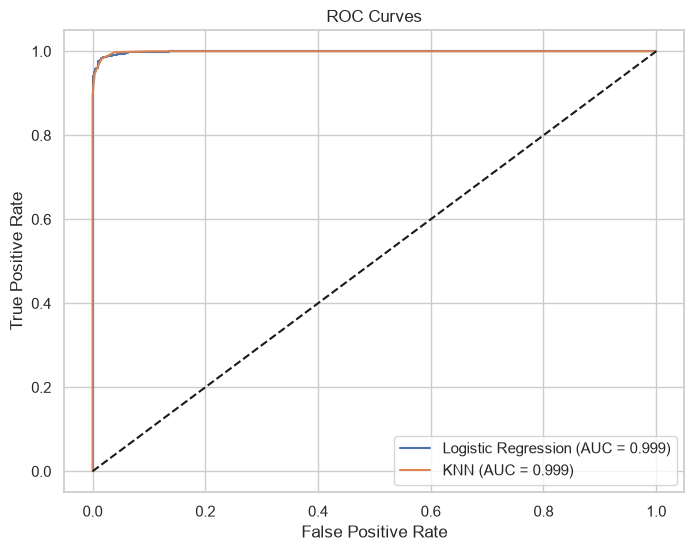

In [52]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

for name, model in {
    "Logistic Regression": log_reg,
    "KNN": knn
}.items():

    probs = model.predict_proba(X_test)[:,1]

    fpr, tpr, _ = roc_curve(
        y_test,
        probs,
        pos_label="human"
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {roc_auc:.3f})"
    )

plt.plot([0,1],[0,1],'k--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves")
plt.legend()
plt.show()

In [53]:
from sklearn.model_selection import cross_val_score

for name, model in models.items():

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,
        scoring="accuracy"
    )

    print(
        f"{name}: "
        f"{scores.mean():.4f} "
        f"(± {scores.std():.4f})"
    )

Logistic Regression: 0.9789 (± 0.0024)
KNN: 0.9792 (± 0.0034)
Decision Tree: 0.9235 (± 0.0046)
